In [1]:
'''
tinkering for redo everything
'''

'\ntinkering for redo everything\n'

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm


import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from tensorflow import keras
import get_postage_stamps as gpsf
import fitting

from scipy.ndimage import sobel
from scipy.signal import find_peaks

2025-11-24 20:15:28.330850: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [37]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [10]:
fname = "ztf_20221020138241_000686_zi_c02_x_0006.fits.fz1alllist"

In [11]:
df= pd.read_csv("/lustre/lrspec/ZTF_data/science_extractions/1020/"+fname)

In [13]:
fname[-8]

'1'

In [7]:
df_nocr = df[df["type"] != "cr"]
df_noboth = df_nocr[df_nocr["type"] != "both"]
df_reduced_edges= rff.reduce_edges(df_noboth, 15)
df_reduced_edges["quad"] = np.full(len(df_reduced_edges), 

Number of transient candidates reduced from 490 to 486.


In [8]:
df_reduced_edges

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size
1,1,ztf_20221020138241_000686_zi_c02_x_0006.,pos,28.960000,488.320000,25.0
2,2,ztf_20221020138241_000686_zi_c02_x_0006.,pos,39.500000,2968.000000,4.0
3,3,ztf_20221020138241_000686_zi_c02_x_0006.,pos,46.666667,488.666667,9.0
4,4,ztf_20221020138241_000686_zi_c02_x_0006.,pos,61.500000,489.000000,10.0
5,5,ztf_20221020138241_000686_zi_c02_x_0006.,pos,88.043478,488.434783,23.0
...,...,...,...,...,...,...
483,483,ztf_20221020138241_000686_zi_c02_x_0006.,neg,2918.500000,2247.500000,6.0
484,484,ztf_20221020138241_000686_zi_c02_x_0006.,neg,2944.000000,369.000000,1.0
485,485,ztf_20221020138241_000686_zi_c02_x_0006.,neg,2956.000000,2248.166667,6.0
486,486,ztf_20221020138241_000686_zi_c02_x_0006.,neg,2993.000000,2248.000000,5.0


In [ ]:
image = ztf_20221020138241_000686_zi_c02_x_0006.

In [34]:
fname[:-8]

'ztf_20221020138241_000686_zi_c02_x_0006.fits.fz'

In [35]:
fpath = (
                        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
                        + "1020"
                        + "_minus_extras/"
                    )
path = fpath + fname[:-8]
hdul = fits.open(path)
file1_array = hdul[1].data

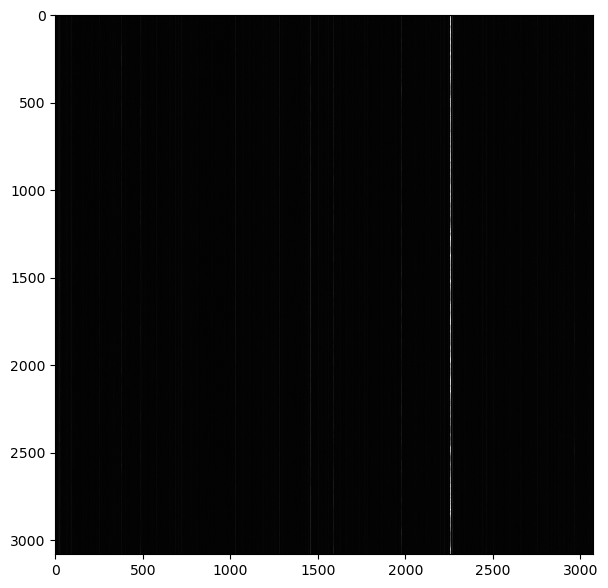

In [38]:
plt.imshow(file1_array)

In [22]:
#now to match to stars
#didn't i just do that or something ugh
xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
xy_file = xy_path+fname[:-20]+fname[-8]+".fits"


In [54]:
df_reduced_edges

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size
1,1,ztf_20221020138241_000686_zi_c02_x_0006.,pos,28.960000,488.320000,25.0
2,2,ztf_20221020138241_000686_zi_c02_x_0006.,pos,39.500000,2968.000000,4.0
3,3,ztf_20221020138241_000686_zi_c02_x_0006.,pos,46.666667,488.666667,9.0
4,4,ztf_20221020138241_000686_zi_c02_x_0006.,pos,61.500000,489.000000,10.0
5,5,ztf_20221020138241_000686_zi_c02_x_0006.,pos,88.043478,488.434783,23.0
...,...,...,...,...,...,...
483,483,ztf_20221020138241_000686_zi_c02_x_0006.,neg,2918.500000,2247.500000,6.0
484,484,ztf_20221020138241_000686_zi_c02_x_0006.,neg,2944.000000,369.000000,1.0
485,485,ztf_20221020138241_000686_zi_c02_x_0006.,neg,2956.000000,2248.166667,6.0
486,486,ztf_20221020138241_000686_zi_c02_x_0006.,neg,2993.000000,2248.000000,5.0


In [62]:
quad = fname[-8]

In [63]:
quad

'1'

In [59]:
df_reduced_edges['filename']

'ztf_20221020138241_000686_zi_c02_x_0006.fits.fz1alllist'

In [65]:
df_nocr = df[df["type"] != "cr"]
df_noboth = df_nocr[df_nocr["type"] != "both"]
df_reduced_edges= rff.reduce_edges(df_noboth, 15)


quad = file[-8]
newpath = path+"/redo_nov/"

xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
xy_file = xy_path+file[:-20]+quad+".fits"

data_list = []


# closest_amounts_c = []
with fits.open(xy_file) as hdul_xy:
    for i, rrow in df_reduced_edges.iterrows():
        row = rrow["row_from_nn"]
        target_x = row+10
    # print(xy_file)
        data = hdul_xy[1].data  
        stored_x = data["X"][:25]  # Column "X"
        stored_y = data["Y"][:25]
        closest_idx = np.argmin(np.abs(stored_x - target_x))
        closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
        print("Diff:",np.abs(closest_x-target_x))
        closest_amounts_c.append(np.abs(closest_x-target_x))
        if np.abs(closest_x-target_x)<=5:
            # plt.imshow(np.sqrt(file1_array[(int(closest_y))-20:(int(closest_y))+20, (int(closest_x))-20:(int(closest_x))+20]))
            # plt.scatter(20,20)
            # plt.show()    
                # Retrieve the closest (x, y) match
            data_list.append({"filename": rrow["filename"], "quad":quad, "type":rrow["type"],"row_from_nn":rrow["row_from_nn"],  
                              "col_from_nn":rrow["col_from_nn"], "detection_size":rrow["detection_size"],
                             "closest_x": closest_x, "closest_y":closest_y, "Diff":np.abs(closest_x-target_x)})
            dframe = pd.DataFrame(data_list)
            dframe.to_csv(newpath+file+"_matched")

Diff: 15.96
Diff: 26.5
Diff: 33.66666666666666
Diff: 21.5
Diff: 5.043478260869563
Diff: 3.0
Diff: 5.0
Diff: 15.5
Diff: 14.0
Diff: 0.09999999999999432
Diff: 0.3333333333333144
Diff: 7.307692307692321
Diff: 4.0
Diff: 11.5
Diff: 10.0
Diff: 30.0
Diff: 27.5
Diff: 37.85714285714289
Diff: 41.54545454545453
Diff: 34.5
Diff: 27.071428571428555
Diff: 24.33333333333337
Diff: 15.0
Diff: 11.0
Diff: 4.0
Diff: 2.8888888888888857
Diff: 2.9545454545454675
Diff: 10.0
Diff: 19.5
Diff: 18.899999999999977
Diff: 27.5
Diff: 36.84615384615387
Diff: 46.04545454545456
Diff: 60.0
Diff: 61.0
Diff: 54.0
Diff: 46.0
Diff: 43.823529411764696
Diff: 32.5
Diff: 28.0
Diff: 22.0
Diff: 16.5
Diff: 16.5
Diff: 2.5
Diff: 3.5
Diff: 13.5
Diff: 30.5
Diff: 26.5
Diff: 48.0
Diff: 45.72222222222223
Diff: 49.0
Diff: 32.0
Diff: 26.0
Diff: 15.5
Diff: 1.9722222222222285
Diff: 9.5
Diff: 11.625
Diff: 30.0
Diff: 26.0
Diff: 35.5
Diff: 47.0
Diff: 54.299999999999955
Diff: 65.5
Diff: 72.5
Diff: 93.37931034482756
Diff: 98.5
Diff: 112.0
Diff: 117

In [66]:
pd.DataFrame(data_list)

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff
0,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,86.000000,2967.000000,1.0,93.0,1941.0,3.000000
1,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,88.000000,2968.000000,1.0,93.0,1941.0,5.000000
2,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,119.100000,488.600000,20.0,129.0,1089.0,0.100000
3,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,119.333333,2967.555556,9.0,129.0,1089.0,0.333333
4,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,147.000000,2968.000000,3.0,153.0,1252.0,4.000000
5,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,232.000000,380.000000,11.0,238.0,1353.0,4.000000
6,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,230.888889,2967.111111,9.0,238.0,1353.0,2.888889
7,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,239.045455,489.090909,22.0,252.0,1765.0,2.954545
8,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,367.500000,489.000000,6.0,380.0,1860.0,2.500000
9,ztf_20221020138241_000686_zi_c02_x_0006.,1,pos,373.500000,2967.000000,12.0,380.0,1860.0,3.500000


(array([152., 109.,  79.,  47.,  37.,  23.,  15.,  17.,   5.,   2.]),
 array([ 0. ,  5.4, 10.8, 16.2, 21.6, 27. , 32.4, 37.8, 43.2, 48.6, 54. ]),
 <BarContainer object of 10 artists>)

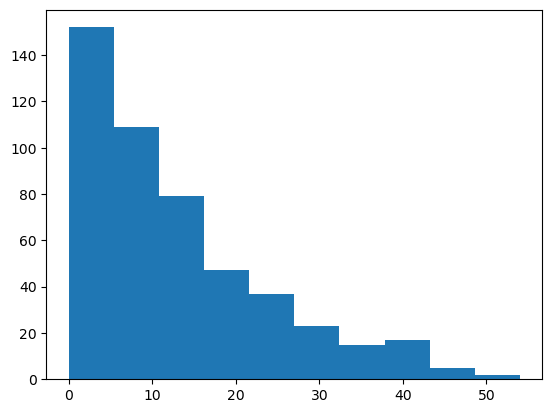

In [28]:
plt.hist(closest_amounts)

(array([82., 46., 29.,  6.,  9.,  6.,  8.,  5.,  8.,  6.]),
 array([  0.,  27.,  54.,  81., 108., 135., 162., 189., 216., 243., 270.]),
 <BarContainer object of 10 artists>)

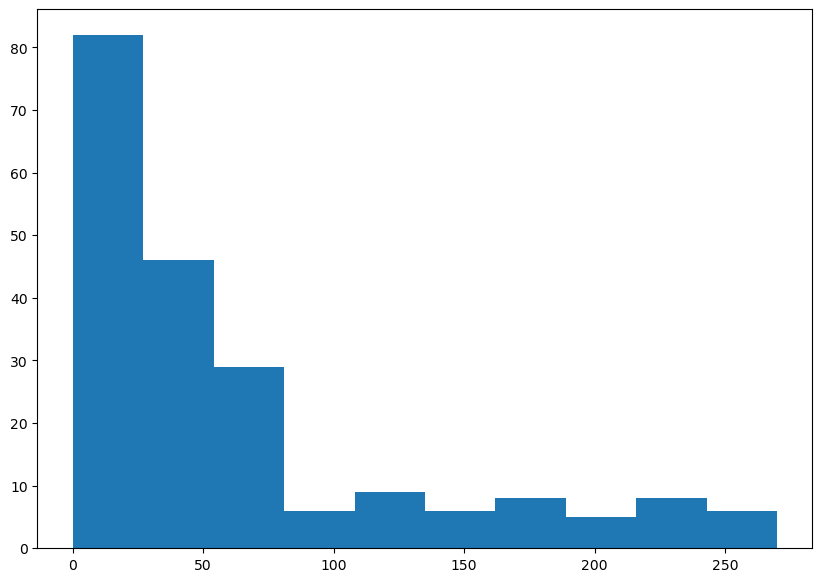

In [46]:
plt.hist(closest_amounts_c)

In [ ]:
data_list = []

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    # image_filename_full = os.path.join(image_path, image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = os.path.join(info_path, info_filename)
    print(image_filename)
    quad = image_filename[-12]
    print(quad)
    
    xy_file = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"+image_filename[:-19]+"_"+str(quad)+".fits"
    print(xy_file)
    # Load data
    infos = np.load(info_filename_full)

    # Convert infos to a NumPy array
    infos_arr = np.array(infos)
    
    header_file = fpath_header+image_filename[:-19]+"_"+str(quad)+".wcs"
    print(header_file)
    with fits.open(xy_file) as hdul_xy:
        data = hdul_xy[1].data  
        stored_x = data["X"]  # Column "X"
        stored_y = data["Y"]
        with fits.open(header_file) as hdul_header:
            wcs = WCS(hdul_header[0].header, relax=True)
            # print(hdul_header[0].header.cards)
            # print(wcs)
        # break
        for row in infos_arr:
            target_x = row[2]  # Replace with your x value

            # Find the index of the closest x-coordinate
            closest_idx = np.argmin(np.abs(stored_x - target_x))
            
            # Retrieve the closest (x, y) match
            closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
            # print(closest_x, closest_y )
            # print("Diff:",np.abs(closest_x-target_x))
            
            #get the RA and Dec
            ra, dec = wcs.all_pix2world(closest_x, closest_y, True)
            data_list.append({"filename": image_filename, **dict(enumerate(row)), 
                             "closest_x": closest_x, "closest_y":closest_y, "Diff":np.abs(closest_x-target_x), 
                             "star_ra":ra, "star_dec":dec})


In [19]:
xy_file

'/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c02_x_1.fits'

In [20]:
idk = pd.read_csv("/home/3155/inference_star_positions")

In [21]:
idk

,Unnamed: 0,0,1,2,3,4,filename,type,row_from_nn,col_from_nn,...,quadrant,sobel_ratio,snr_center,snr_max,snr_min,closest_x,closest_y,Diff,star_ra,star_dec
0,0,1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,1208.750000,...,4,12.620198,3.551599,3.661652,-3.093721,1218.0,2209.0,0.750000,22.621652,2.969776
1,1,3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,1209.500000,...,4,9.809223,3.095683,3.140310,-0.995967,1218.0,2209.0,1.500000,22.621652,2.969776
2,2,4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,647.000000,1209.928571,...,4,12.620198,-1.530615,3.552551,-3.001541,1218.0,2209.0,1.928571,22.621652,2.969776
3,3,24,0,0,3,3,ztf_20221020163819_000640_zg_c01_x_0021.,pos,49.727273,2908.454545,...,1,15.091165,2.953927,3.694576,-1.642830,2920.0,2237.0,1.545455,303.875960,23.509883
4,4,25,1,1,28,28,ztf_20221020163819_000640_zg_c01_x_0021.,pos,298.000000,2908.833333,...,1,14.822262,-0.201039,0.347701,-3.373438,2920.0,2237.0,1.166667,303.875960,23.509883
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51088,51088,610705,70,70,171,171,ztf_20221020297847_000449_zr_c14_x_0026.,neg,1094.000000,1320.615385,...,4,20.657988,0.712186,3.388600,0.263476,1331.0,823.0,0.384615,20.736022,7.189586
51089,51089,610710,75,75,176,176,ztf_20221020297847_000449_zr_c14_x_0026.,neg,1210.300000,1321.400000,...,4,14.701658,0.601663,3.700257,0.536696,1331.0,823.0,0.400000,20.736022,7.189586
51090,51090,610739,104,104,231,231,ztf_20221020297847_000449_zr_c14_x_0026.,neg,2124.777778,1320.111111,...,4,13.061511,-3.007695,1.359507,-3.470040,1331.0,823.0,0.888889,20.736022,7.189586
51091,51091,610746,111,111,243,243,ztf_20221020297847_000449_zr_c14_x_0026.,neg,2333.500000,1319.714286,...,4,12.815176,-2.797584,-1.147434,-3.048873,1331.0,823.0,1.285714,20.736022,7.189586


In [67]:
ppath = "/lustre/lrspec/ZTF_data/science_extractions/1020/redo_nov/"

In [72]:
test = pd.read_csv(ppath + "ztf_20221020297847_000449_zr_c16_x_0022.fits.fz1alllist_matched")

In [73]:
test

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff
0,0,ztf_20221020297847_000449_zr_c16_x_0022.,1,pos,558.000000,250.000000,3,564.0,2800.0,4.000000
1,1,ztf_20221020297847_000449_zr_c16_x_0022.,1,pos,1626.000000,251.000000,1,1633.0,2803.0,3.000000
2,2,ztf_20221020297847_000449_zr_c16_x_0022.,1,neg,97.000000,1092.500000,2,109.0,2556.0,2.000000
3,3,ztf_20221020297847_000449_zr_c16_x_0022.,1,neg,274.500000,251.000000,2,281.0,2317.0,3.500000
4,4,ztf_20221020297847_000449_zr_c16_x_0022.,1,neg,551.142857,250.428571,7,564.0,2800.0,2.857143
5,5,ztf_20221020297847_000449_zr_c16_x_0022.,1,neg,920.500000,250.000000,2,931.0,1267.0,0.500000
6,6,ztf_20221020297847_000449_zr_c16_x_0022.,1,neg,2425.000000,257.000000,1,2432.0,100.0,3.000000


In [77]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/df_sobel*

/lustre/lrspec/ZTF_data/efficiency_testing/df_sobel_neg
/lustre/lrspec/ZTF_data/efficiency_testing/df_sobel_pos


In [79]:
df = pd.read_csv(ppath+"df_all")

/tmp/ipykernel_2427/1259852760.py:1: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ppath+"df_all")


In [80]:
len(df)

436070

In [ ]:

for f in files:
    df = pd.read_csv(os.path.join(newpath, f))
    # df["quadrant"] = f[-8]  # Add the filename as a new column
    dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df = pd.concat(dataframes, ignore_index=True)


In [81]:
# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)

dataframes = []
# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("_snr")
]  # Adjust this to your file format


# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for number, f in enumerate(files):

    df = pd.read_csv(os.path.join(folder_path, f))
    dataframes.append(df)
concatenated_df = pd.concat(dataframes, ignore_index=True)
    # dataframes.append(df)

In [135]:
almost_bigs = concatenated_df[concatenated_df['snr_center']>6]

In [146]:
len(concatenated_df)

610903

In [89]:
bigs["filename"].iloc[0][:-5]

'ztf_20221020141806_000686_zi_c15_x_'

In [136]:
data_list = []
for i, rrow in almost_bigs.iterrows():
    file = rrow["filename"]
    newpath = folder_path+"/redo_nov/"
    
    xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
    xy_file = xy_path+file[:-5]+quad+".fits"
    
    
    
    
    # closest_amounts_c = []
    with fits.open(xy_file) as hdul_xy:
        row = rrow["row_from_nn"]
        target_x = row+10
    # print(xy_file)
        data = hdul_xy[1].data  
        stored_x = data["X"][:25]  # Column "X"
        stored_y = data["Y"][:25]
        closest_idx = np.argmin(np.abs(stored_x - target_x))
        closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
        # plt.imshow(np.sqrt(file1_array[(int(closest_y))-20:(int(closest_y))+20, (int(closest_x))-20:(int(closest_x))+20]))
        # plt.scatter(20,20)
        # plt.show()    
            # Retrieve the closest (x, y) match
        data_list.append({"filename": rrow["filename"], "quadrant":rrow["quadrant"], "type":rrow["type"],"row_from_nn":rrow["row_from_nn"],  
                          "col_from_nn":rrow["col_from_nn"], "detection_size":rrow["detection_size"],"snr_center":rrow['snr_center'],
                         "closest_x": closest_x, "closest_y":closest_y, "Diff":np.abs(closest_x-target_x)})
dframe = pd.DataFrame(data_list)
            # dframe.to_csv(newpath+file+"_matched")

In [126]:
dframe

,filename,quadrant,type,row_from_nn,col_from_nn,detection_size,snr_center,closest_x,closest_y,Diff
0,ztf_20221020148032_000686_zg_c16_x_0014.,4,pos,2884.410695,514.209626,935.0,16.718662,2966.0,2020.0,71.589305
1,ztf_20221020148032_000686_zg_c16_x_0014.,4,both,2884.410695,514.209626,935.0,16.718662,2966.0,2020.0,71.589305
2,ztf_20221020141806_000686_zi_c15_x_0009.,3,neg,2401.500000,2194.000000,6.0,27.410943,2385.0,2331.0,26.500000
3,ztf_20221020141806_000686_zi_c15_x_0009.,3,both,2401.500000,2194.000000,6.0,27.410943,2385.0,2331.0,26.500000
4,ztf_20221020154120_000640_zi_c08_x_0014.,4,pos,1371.872727,1975.690909,55.0,12.137993,1426.0,551.0,44.127273
...,...,...,...,...,...,...,...,...,...,...
179,ztf_20221020138241_000686_zi_c16_x_0026.,3,both,2501.000000,2565.000000,5.0,49.892266,2506.0,431.0,5.000000
180,ztf_20221020138241_000686_zi_c16_x_0026.,3,both,2511.000000,2560.000000,7.0,44.170030,2506.0,431.0,15.000000
181,ztf_20221020138241_000686_zi_c16_x_0026.,3,both,2516.000000,2566.000000,5.0,47.335816,2506.0,431.0,20.000000
182,ztf_20221020141806_000686_zi_c16_x_0024.,3,pos,2057.133333,1051.383333,60.0,13.713944,1974.0,1278.0,93.133333


In [137]:
np.unique(dframe["filename"])

array(['ztf_20221020138241_000686_zi_c02_x_0029.',
       'ztf_20221020138241_000686_zi_c08_x_0009.',
       'ztf_20221020138241_000686_zi_c14_x_0015.',
       'ztf_20221020138241_000686_zi_c16_x_0026.',
       'ztf_20221020141806_000686_zi_c15_x_0009.',
       'ztf_20221020141806_000686_zi_c16_x_0024.',
       'ztf_20221020148032_000686_zg_c09_x_0003.',
       'ztf_20221020148032_000686_zg_c09_x_0007.',
       'ztf_20221020148032_000686_zg_c09_x_0020.',
       'ztf_20221020148032_000686_zg_c15_x_0029.',
       'ztf_20221020148032_000686_zg_c16_x_0014.',
       'ztf_20221020154120_000640_zi_c08_x_0014.',
       'ztf_20221020154120_000640_zi_c11_x_0015.',
       'ztf_20221020157697_000640_zi_c09_x_0025.',
       'ztf_20221020157697_000640_zi_c11_x_0015.',
       'ztf_20221020157697_000640_zi_c11_x_0027.',
       'ztf_20221020157697_000640_zi_c16_x_0019.',
       'ztf_20221020157697_000640_zi_c16_x_0023.',
       'ztf_20221020163819_000640_zg_c12_x_0001.',
       'ztf_20221020163819_0006

In [107]:
import importlib

In [108]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [144]:
dframe[dframe["filename"]=="ztf_20221020148032_000686_zg_c09_x_0020."]

,filename,quadrant,type,row_from_nn,col_from_nn,detection_size,snr_center,closest_x,closest_y,Diff
10,ztf_20221020148032_000686_zg_c09_x_0020.,4,neg,1095.450549,154.395604,91.0,6.248637,1109.0,1470.0,3.549451


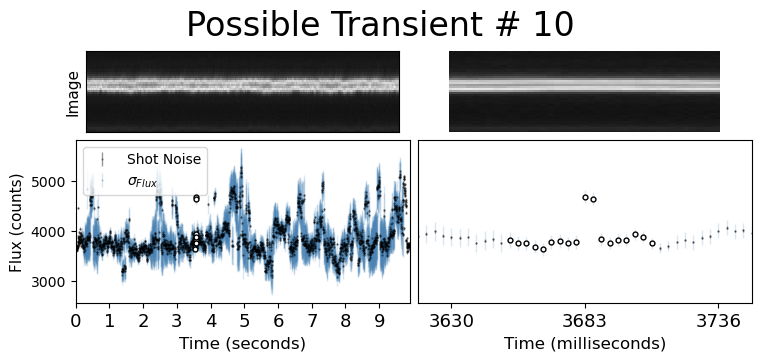

In [145]:
rff.plot_time_series_again_aperture(dframe, 10)

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

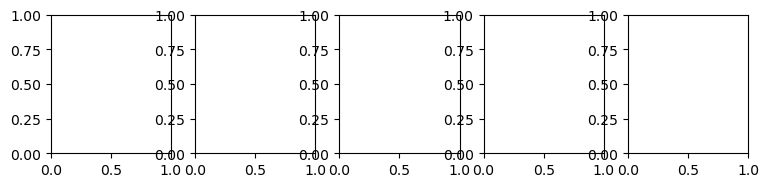

In [129]:
rff.inspect_df_with_quadrant(dframe[dframe["filename"]=="ztf_20221020148032_000686_zg_c16_x_0014."], "1020",30)

In [116]:
dframe.index

RangeIndex(start=0, stop=178, step=1)

In [123]:
dframe

,filename,quadrant,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff
0,ztf_20221020141806_000686_zi_c15_x_0009.,3,neg,2401.50,2194.00,6.0,2385.0,2331.0,26.50
1,ztf_20221020141806_000686_zi_c15_x_0009.,3,both,2401.50,2194.00,6.0,2385.0,2331.0,26.50
2,ztf_20221020138241_000686_zi_c16_x_0026.,3,pos,329.00,2441.00,5.0,377.0,2959.0,38.00
3,ztf_20221020138241_000686_zi_c16_x_0026.,3,pos,412.00,2439.00,5.0,419.0,2870.0,3.00
4,ztf_20221020138241_000686_zi_c16_x_0026.,3,pos,414.00,2446.00,5.0,419.0,2870.0,5.00
...,...,...,...,...,...,...,...,...,...
173,ztf_20221020138241_000686_zi_c16_x_0026.,3,both,2485.75,2564.25,8.0,2506.0,431.0,10.25
174,ztf_20221020138241_000686_zi_c16_x_0026.,3,both,2495.50,2559.00,6.0,2506.0,431.0,0.50
175,ztf_20221020138241_000686_zi_c16_x_0026.,3,both,2501.00,2565.00,5.0,2506.0,431.0,5.00
176,ztf_20221020138241_000686_zi_c16_x_0026.,3,both,2511.00,2560.00,7.0,2506.0,431.0,15.00


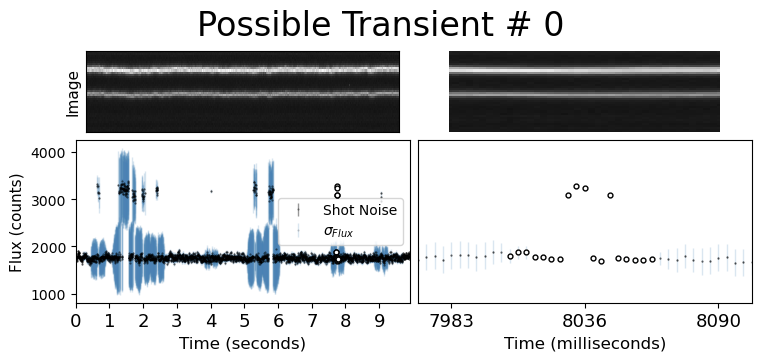

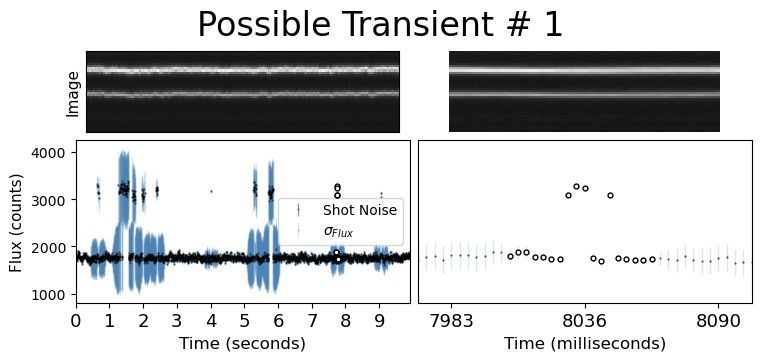

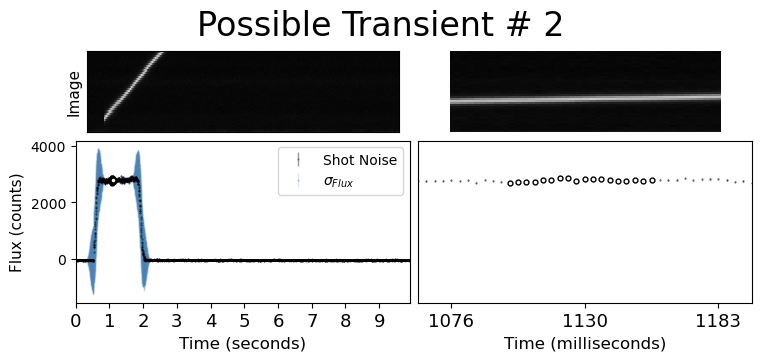

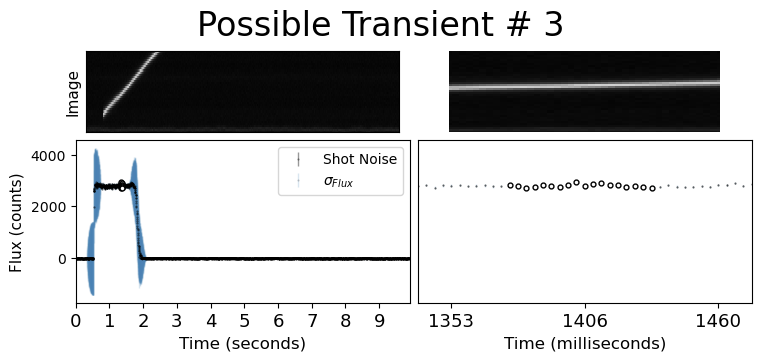

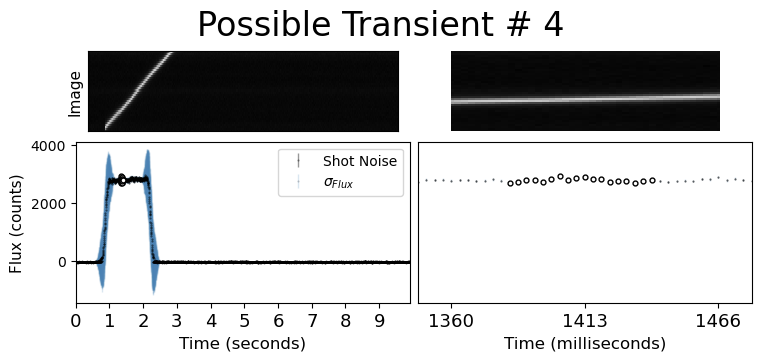

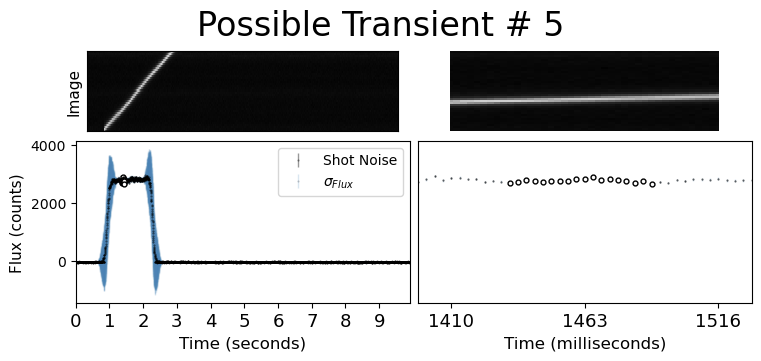

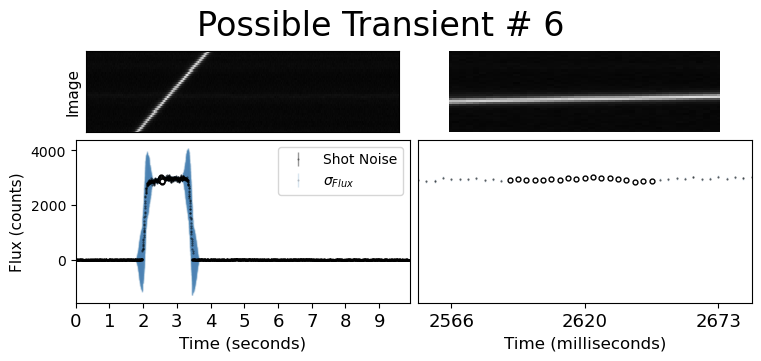

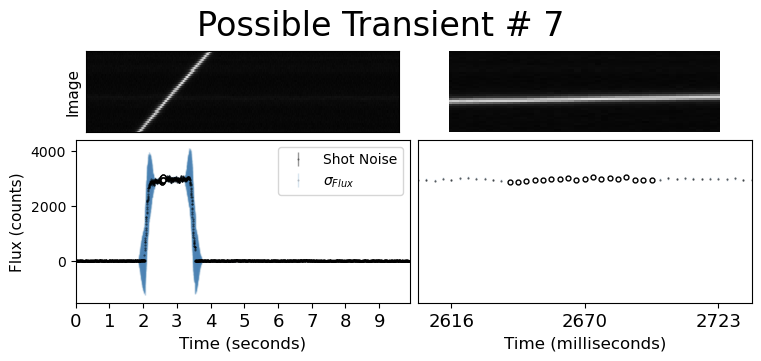

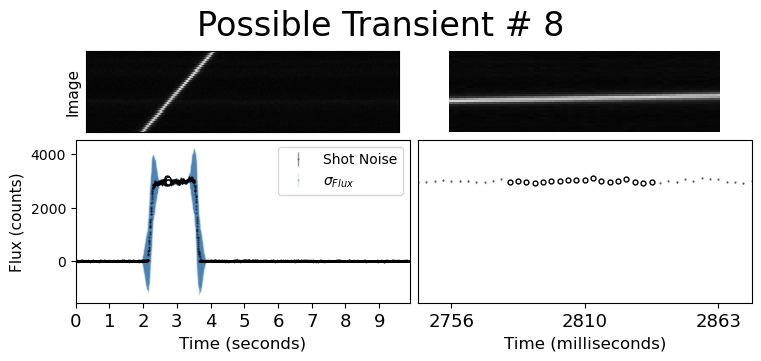

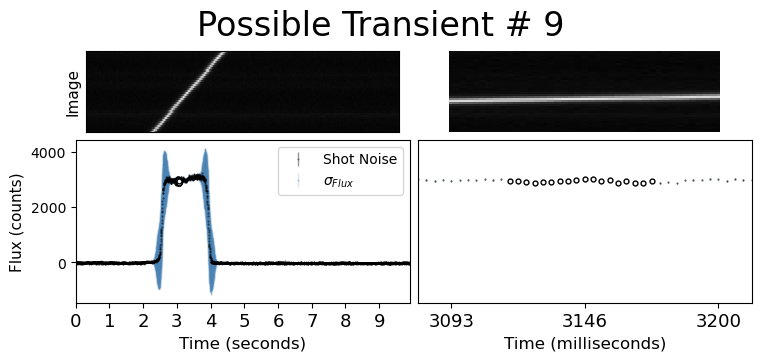

In [122]:
for index in dframe.index[:10]:
    rff.plot_time_series_again_aperture(dframe, index)